In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import ttest_ind
from scipy.stats import normaltest
from scipy.stats import mannwhitneyu
from statsmodels.stats.proportion import proportions_ztest
from scipy.stats import bootstrap
from scipy.stats import chisquare
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize
from scipy.stats import norm

## Гипотеза и метрики

Изменение: перенос первых ворот с 30-го уровня (control) на 40-й (test).
Единица разбиения: игрок. Группы: control = gate_30, test = gate_40.

Гипотеза: более поздние ворота улучшат удержание игроков.

Главная метрика: доля вернувшихся на 7-й день (retention_7). Выше значит лучше.
Это прокси долгосрочной вовлечённости.

Вторичные метрики (объясняют):
- доля вернувшихся на 1-й день (retention_1);
- доля игроков, сыгравших от 30 до 40 раундов (диагностика механизма).

Защитная метрика (не должна ухудшиться):
- число сыгранных раундов (вовлечённость), смотрим медиану.
(Идеально была бы ещё выручка или доля платящих, но таких данных в наборе нет.)

Правила анализа: двусторонние тесты, α = 0.05, порог SRM = 0.001.
Правило решения: запускаем test, только если retention_7 значимо вырос и защитная
метрика не ухудшилась.

MDE and power
power = 0.8
MDE

In [2]:
df = pd.read_csv("cookie_cats.csv")
print(df.isna().sum())
df['retention_1'] = df['retention_1'].astype(int)
df['retention_7'] = df['retention_7'].astype(int)


userid            0
version           0
sum_gamerounds    0
retention_1       0
retention_7       0
dtype: int64


In [3]:
count_control_group = df.query("version == 'gate_30'").userid.count()
count_test_group = df.query("version == 'gate_40'").userid.count()
all_users = count_control_group + count_test_group

expected = [all_users * 0.5, all_users * 0.5]
our_data = [count_control_group, count_test_group]
chisquare(our_data, expected)

Power_divergenceResult(statistic=np.float64(6.9024049496058275), pvalue=np.float64(0.008607987810836243))

***SRM***

При тесте на честность распределения групп p-value получился 0.0086, это больше порога 0.001, поэтому SRM не обнаружен и группы разбиты честно. Но с одной оговоркой: значение довольно близко к порогу, и нужно учитывать, не повлияло ли это на результаты тестов.

***retention_1** - вернулся ли игрок на следующий день после регистрации (0 или 1)\
**retention_7** - вернулся ли игрок через неделю после регистрации (0 или 1)\
**version** - версия игры\
**test** - game_40;\
**control** - game_30*

Также удален был один выброс по причине подозрения в боте слишком высокие показатели сыграных раундов

In [4]:
df['version'] = df['version'].replace({'gate_40': 'test', 'gate_30': 'control'})
print(df.sort_values('sum_gamerounds', ascending=False).head(1))
df = df.query("sum_gamerounds != 49854")
df.head()

        userid  version  sum_gamerounds  retention_1  retention_7
57702  6390605  control           49854            0            1


,userid,version,sum_gamerounds,retention_1,retention_7
0,116,control,3,0,0
1,337,control,38,1,0
2,377,test,165,1,0
3,483,test,1,0,0
4,488,test,179,1,1


In [5]:
df_control = df.query("version == 'control'")
df_test = df.query("version == 'test'")

In [6]:
# t-тест по среднему (для сравнения), основной тест для раундов - Манн-Уитни
print(ttest_ind(df_control.sum_gamerounds, df_test.sum_gamerounds))
print(normaltest(df_control.sum_gamerounds))
print(mannwhitneyu(df_control.sum_gamerounds, df_test.sum_gamerounds))

TtestResult(statistic=np.float64(0.0633675766982082), pvalue=np.float64(0.9494739458256001), df=np.float64(90186.0))
NormaltestResult(statistic=np.float64(51730.04355110887), pvalue=np.float64(0.0))
MannwhitneyuResult(statistic=np.float64(1024285761.5), pvalue=np.float64(0.05089155279145375))


In [7]:
sum_success_ctrl_7 = df_control.retention_7.sum()
all_sum_ctrl_7 = df_control.retention_7.count()

sum_success_test_7 = df_test.retention_7.sum()
all_sum_test_7 = df_test.retention_7.count()

success_7 = [sum_success_ctrl_7, sum_success_test_7]
all_7 = [all_sum_ctrl_7, all_sum_test_7]

dolya_7_test = sum_success_test_7/all_sum_test_7
dolya_7_control = sum_success_ctrl_7/all_sum_ctrl_7

proportions_ztest(count=success_7, nobs=all_7)


(np.float64(3.1574100858819936), np.float64(0.001591773177399344))

In [8]:
sum_success_ctrl_1 = df_control.retention_1.sum()
all_sum_ctrl_1 = df_control.retention_1.count()

sum_success_test_1 = df_test.retention_1.sum()
all_sum_test_1 = df_test.retention_1.count()

success_1 = [sum_success_ctrl_1, sum_success_test_1]
all_1 = [all_sum_ctrl_1, all_sum_test_1]

dolya_1_test = sum_success_test_1/all_sum_test_1
dolya_1_control = sum_success_ctrl_1/all_sum_ctrl_1

proportions_ztest(count=success_1, nobs=all_1)

(np.float64(1.787103509763628), np.float64(0.0739207603418346))

In [9]:
dif_7_ret = dolya_7_test - dolya_7_control
dif_1_ret = dolya_1_test - dolya_1_control
print(dif_7_ret, dif_1_ret)

-0.00818318160884296 -0.005915196587034155


In [10]:
var_7_test = ((dolya_7_test * (1 - dolya_7_test))/all_sum_test_7)
var_7_control = ((dolya_7_control * (1 - dolya_7_control))/all_sum_ctrl_7)
se = (var_7_test + var_7_control) ** 0.5
confidence_interval_7 = [(dolya_7_test - dolya_7_control) - 1.96 * se, (dolya_7_test - dolya_7_control) + 1.96 * se]
confidence_interval_7

[np.float64(-0.013263463260905021), np.float64(-0.0031028999567808985)]

In [11]:
var_1_test = ((dolya_1_test * (1 - dolya_1_test))/all_sum_test_1)
var_1_control = ((dolya_1_control * (1 - dolya_1_control))/all_sum_ctrl_1)
se_1 = (var_1_test + var_1_control) ** 0.5
confidence_interval_1 = [(dolya_1_test - dolya_1_control) - 1.96 * se_1, (dolya_1_test - dolya_1_control) + 1.96 * se_1]
confidence_interval_1

[np.float64(-0.01240262898665639), np.float64(0.0005722358125880792)]

*Ретеншен 1-го дня в тестовой группе в выборке оказался ниже на 0.6 п.п. (95% доверительный интервал для разницы: от −1.2 до 0.06 п.п.). Интервал включает ноль, и p-value ≈ 0.07 больше 0.05, поэтому разница статистически не значима: на уровне 5% мы не можем отвергнуть нулевую гипотезу об отсутствии эффекта. Это не значит, что эффекта нет: по retention_1 данных недостаточно, чтобы сказать, есть ли разница. Направление при этом такое же, как у retention_7 (в test ниже), но значимой разница оказалась только на 7-й день. Retention_1 вторичная метрика и лишь поясняет результат, а решение принимается по главной метрике retention_7.*

*Ретеншен 7-го дня в тестовой группе оказался ниже на 0.8 п.п. (95% доверительный интервал для снижения: от 0.3 до 1.3 п.п.). Если бы компания привлекла 100 000 новых игроков и оставила обновление для всех, к 7-му дню вернулось бы примерно на 310–1326 игроков меньше, чем без обновления. Интервал не включает ноль, и p-value меньше 0.05, поэтому разница статистически значима: на уровне 5% мы отвергаем гипотезу об отсутствии эффекта. Это оценка по выборке, а не точный прогноз: реальные потери могут отличаться, но, скорее всего, находятся в указанных границах.*

In [12]:
gamers_loss_1 = (confidence_interval_7[1] * 100 * -1) * 100000 / 100
gamers_loss_2 = (confidence_interval_7[0] * 100 * -1) * 100000 / 100

print(gamers_loss_1, gamers_loss_2)

310.28999567808984 1326.3463260905023


In [13]:
df_control_only_7 = df_control.query("retention_7 == 1")
df_test_only_7 = df_test.query("retention_7 == 1")

In [14]:
print(df_control_only_7.sum_gamerounds.median())
print(df_control_only_7.sum_gamerounds.mean())

105.0
160.1175155864016


In [15]:
print(df_test_only_7.sum_gamerounds.median())
print(df_test_only_7.sum_gamerounds.mean())

111.0
165.6498369368281


In [16]:
res_ctrl = bootstrap((df_control_only_7['sum_gamerounds'],), np.median, n_resamples=10000, method='percentile', vectorized=False, random_state=42)
res_test = bootstrap((df_test_only_7['sum_gamerounds'],), np.median, n_resamples=10000, method='percentile', vectorized=False, random_state=42)

res_ctrl_mean = bootstrap((df_control_only_7['sum_gamerounds'],), np.mean, n_resamples=10000, method='percentile', vectorized=False, random_state=42)
res_test_mean = bootstrap((df_test_only_7['sum_gamerounds'],), np.mean, n_resamples=10000, method='percentile', vectorized=False, random_state=42)



In [17]:
print(res_ctrl)
print(res_test)
print(res_ctrl_mean)
print(res_test_mean)

BootstrapResult(confidence_interval=ConfidenceInterval(low=np.float64(101.0), high=np.float64(108.0)), bootstrap_distribution=array([103., 107., 108., ..., 102., 101., 103.]), standard_error=np.float64(1.8726402959906145))
BootstrapResult(confidence_interval=ConfidenceInterval(low=np.float64(108.0), high=np.float64(114.0)), bootstrap_distribution=array([111., 111., 113., ..., 111., 111., 111.]), standard_error=np.float64(1.451051365392177))
BootstrapResult(confidence_interval=ConfidenceInterval(low=np.float64(156.34820903423127), high=np.float64(163.9025438183743)), bootstrap_distribution=array([158.0697565 , 160.83660746, 163.33948947, ..., 156.30302317,
       156.41383367, 159.17092107]), standard_error=np.float64(1.938891900930144))
BootstrapResult(confidence_interval=ConfidenceInterval(low=np.float64(161.73512501509845), high=np.float64(169.71097958690663)), bootstrap_distribution=array([165.20364778, 164.14989733, 164.83633289, ..., 164.34243266,
       167.11039981, 163.19664211

In [18]:
def dif_of_median(x, y):
    res = np.median(x) - np.median(y)
    return(res)

In [19]:
res_diff_median = bootstrap(
    (df_control_only_7['sum_gamerounds'], df_test_only_7['sum_gamerounds']), 
    statistic=dif_of_median,
    n_resamples=10000,
    method='percentile', random_state=42)

In [20]:
res_diff_median

BootstrapResult(confidence_interval=ConfidenceInterval(low=np.float64(-11.0), high=np.float64(-2.0)), bootstrap_distribution=array([-9., -6., -4., ..., -8., -7., -8.]), standard_error=np.float64(2.347426608260228))

Доверительный интервал разницы медиан раундов (control минус test) среди игроков, вернувшихся на 7-й день, получился от −11 до −2. Ноль в него не входит, значит, среди вернувшихся в test медиана раундов выше примерно на 2–11 раундов (медианы 105 в control и 111 в test). Это описание только тех, кто вернулся, и причинный вывод по нему делать нельзя. В test вернулось меньше игроков, а отбор идёт по результату (вернулся или нет), поэтому группы вернувшихся уже нельзя считать равноценными: это смещение отбора. Возможное объяснение: среди вернувшихся остаются самые вовлечённые игроки, и они играют больше. Можно предположить, что обновление хуже мотивировало игроков возвращаться, но тех, кого всё же удержало, увлекло сильнее, однако это гипотеза, данные её не проверяют. Защитная метрика (число раундов) проверяется на всех игроках, а не на вернувшихся, см. ниже. Наблюдение пригодится как идея для следующего обновления: искать баланс, при котором растут и ретеншен, и число раундов.

In [21]:
res_diff_median_all = bootstrap(
    (df_control['sum_gamerounds'], df_test['sum_gamerounds']), 
    statistic=dif_of_median,
    n_resamples=10000,
    method='percentile', random_state=42)

In [22]:
res_diff_median_all

BootstrapResult(confidence_interval=ConfidenceInterval(low=np.float64(0.0), high=np.float64(1.0)), bootstrap_distribution=array([1., 1., 1., ..., 1., 1., 1.]), standard_error=np.float64(0.2684620032420202))

In [23]:
mannwhitneyu(df_control['sum_gamerounds'], df_test['sum_gamerounds'])


MannwhitneyuResult(statistic=np.float64(1024285761.5), pvalue=np.float64(0.05089155279145375))

Защитная метрика: число сыгранных раундов, смотрим на всех игроках. Распределение раундов сильно скошено вправо (нормальность отвергается), поэтому вместо t-теста по среднему использован критерий Манна-Уитни. Медиана в control равна 17 раундам, в test 16, средние почти совпадают (51.34 и 51.30), для сравнения t-тест по среднему даёт p ≈ 0.95. Бутстрэп-интервал для разницы медиан (control минус test) получился от 0 до 1 раунда: медиана целая, поэтому интервал дискретный, а разница не превышает одного раунда. Критерий Манна-Уитни дал p ≈ 0.051, это больше 0.05, поэтому по заданному правилу значимого различия в распределении раундов нет. Результат пограничный, поэтому мы не утверждаем, что различий нет: значимого ухудшения мы не обнаружили, а возможная разница очень мала. Защитная метрика не блокирует запуск, а решение принимается по главной метрике retention_7.

In [24]:
df_control_30_40 = df_control.query("sum_gamerounds >= 30 and sum_gamerounds <= 40")
df_test_30_40 = df_test.query("sum_gamerounds >= 30 and sum_gamerounds <= 40")

rounds_control_30_40 = df_control_30_40.sum_gamerounds.count()
rounds_test_30_40 = df_test_30_40.sum_gamerounds.count()

rounds_control_all = df_control.sum_gamerounds.count()
rounds_test_all = df_test.sum_gamerounds.count()

proportion_rounds_ctrl = rounds_control_30_40 / rounds_control_all
proportion_rounds_test = rounds_test_30_40 / rounds_test_all

success_propor = [rounds_control_30_40, rounds_test_30_40]
all_propor = [rounds_control_all, rounds_test_all]

z_stat_prop, p_value_prop = proportions_ztest(count=success_propor, nobs=all_propor)
print(z_stat_prop, p_value_prop)


5.336255028149786 9.488591954006085e-08


In [25]:
var_test = ((proportion_rounds_test * (1 - proportion_rounds_test))/rounds_test_all)
var_control = ((proportion_rounds_ctrl * (1 - proportion_rounds_ctrl))/rounds_control_all)
se_rounds = (var_test + var_control) ** 0.5
confidence_interval_rounds = [(proportion_rounds_test - proportion_rounds_ctrl) - 1.96 * se_rounds, (proportion_rounds_test - proportion_rounds_ctrl) + 1.96 * se_rounds]
confidence_interval_rounds

[np.float64(-0.01246092881650923), np.float64(-0.0057643682452717965)]

Нам удалось зафиксировать стат значимое различие между тем какая доля игроков прошла с 30 по 40 раунд в тестовой и контрольной группе. Тест показал что в тестовой группе доля прошедших от 30 до 40 меньше и мы можем выдвинуть гипотезу что это как раз связано со сдвигом игрового гейта

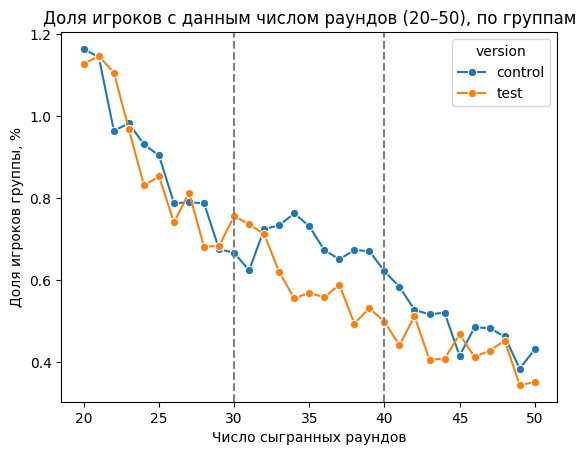

In [26]:
share = (df.groupby("version")["sum_gamerounds"].value_counts(normalize=True).mul(100).rename("share").reset_index())

w = share.query("sum_gamerounds >= 20 and sum_gamerounds <= 50")

ax = sns.lineplot(data=w, x="sum_gamerounds", y="share", hue="version", marker="o")
ax.axvline(30, ls="--", color="gray")
ax.axvline(40, ls="--", color="gray")
ax.set_xlabel("Число сыгранных раундов")
ax.set_ylabel("Доля игроков группы, %")
ax.set_title("Доля игроков с данным числом раундов (20–50), по группам")
plt.show()

Вывод по графику. До 30 раундов доли игроков в control и test почти совпадают: линии идут
близко и пересекаются. Начиная примерно с 32–33 раундов, то есть сразу после места, где в
control стоит ворота, линия control проходит выше линии test, и это сохраняется примерно до
45 раундов. Значит, в диапазоне после 30 раундов в test остаётся заметно меньше игроков,
которые останавливаются именно здесь. Это согласуется с z-тестом по доле игроков с 30–40
раундами (в test она ниже). Резких пиков на отметках 30 и 40 нет: различие распределено по
всему диапазону, а не сосредоточено в одной точке. Каждая отдельная точка графика мала
(порядка 0.5–0.8%) и шумная, поэтому важно не отдельное расхождение, а общая картина по
диапазону. Связь с переносом ворот с 30-го уровня на 40-й это правдоподобная гипотеза, но
по этим данным причину (почему игроки останавливаются или продолжают) мы не доказываем.

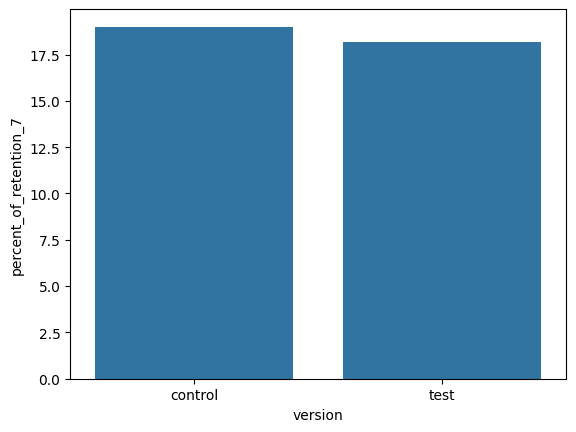

In [27]:
data = {'version': ['control', 'test'], 'percent_of_retention_7': [round(dolya_7_control * 100, 1), round(dolya_7_test * 100, 1)]}
data_sns = pd.DataFrame(data)

sns.barplot(data=data_sns, x='version', y='percent_of_retention_7')
plt.show()

In [28]:
# MDE - минимальная разница долей, которую тест замечает при заданных alpha и мощности
alpha_mde = 0.05
power_mde = 0.8

def calc_mde(p, n1, n2, alpha=alpha_mde, power=power_mde):
    z_alpha = norm.ppf(1 - alpha / 2)  # 1.96
    z_power = norm.ppf(power)          # 0.84
    # SE = sqrt(p * (1 - p) * (1/n1 + 1/n2))
    se = (p * (1 - p) * ((1/n1) + (1/n2))) ** 0.5
    # MDE = (z_alpha + z_power) * SE
    return (z_alpha + z_power) * se

In [29]:
# MDE для retention_7
mde_7 = calc_mde(dolya_7_control, all_sum_ctrl_7, all_sum_test_7)
print(mde_7 * 100)  # в п.п.

# Проверка: сколько игроков нужно, чтобы заметить такую разницу (должно получиться около размера группы)
effect_size_7 = proportion_effectsize(dolya_7_control, dolya_7_control - mde_7)
NormalIndPower().solve_power(effect_size=effect_size_7, alpha=alpha_mde, power=power_mde, nobs1=None, ratio=(all_sum_test_7/all_sum_ctrl_7))

0.7322436354931033


44032.77056059903

In [30]:
# MDE для retention_1
mde_1 = calc_mde(dolya_1_control, all_sum_ctrl_1, all_sum_test_1)
print(mde_1 * 100)  # в п.п.

# Проверка: сколько игроков нужно, чтобы заметить такую разницу
effect_size_1 = proportion_effectsize(dolya_1_control, dolya_1_control - mde_1)
NormalIndPower().solve_power(effect_size=effect_size_1, alpha=alpha_mde, power=power_mde, nobs1=None, ratio=(all_sum_test_1/all_sum_ctrl_1))

0.9279032679531504


44606.77845054894

In [31]:
# Какое падение хотим заметить (0.5 п.п. в долях)
detect1 = 0.005

In [32]:
# Обратная задача: сколько игроков нужно, чтобы заметить падение detect1
p_7 = dolya_7_control
p2_7 = p_7 - detect1

prop_ef_size = proportion_effectsize(p_7, p2_7)
NormalIndPower().solve_power(effect_size=prop_ef_size, alpha=alpha_mde, power=power_mde, nobs1=None, ratio=1)

95726.05282926698

In [33]:
p_1 = dolya_1_control
p2_1 = p_1 - detect1

prop_ef_size2 = proportion_effectsize(p_1, p2_1)

NormalIndPower().solve_power(effect_size=prop_ef_size2, alpha=alpha_mde, power=power_mde, nobs1=None, ratio=1)

155124.33220607188

Мощность и MDE. Тест рассчитан при двустороннем уровне значимости 0.05 и мощности 0.8. Для главной метрики retention_7 (базовый уровень около 19%, примерно 44 700 игроков в control и 45 500 в test) минимальный обнаружимый эффект (MDE) составляет около 0.73 п.п. Наблюдаемая разница 0.8 п.п. чуть выше этого порога, поэтому тест был достаточно мощным, чтобы её заметить, и значимый результат по D7 согласуется с мощностью. MDE считается по базовому уровню и размеру выборки, а не по наблюдаемому эффекту. Для вторичной метрики retention_1 (базовый уровень около 45%) MDE больше, около 0.93 п.п., потому что доля ближе к 50% и метрика шумнее. Наблюдаемая разница по D1 равна 0.6 п.п. и ниже этого порога, поэтому незначимый результат по D1 нельзя читать как отсутствие эффекта: тест недостаточно мощен, чтобы надёжно заметить такую разницу. Обратная задача: сколько игроков нужно в каждой группе, чтобы с мощностью 0.8 заметить падение на 0.5 п.п. При равных группах для retention_7 нужно около 95 700 игроков, для retention_1 около 155 100. Это примерно в 2 и в 3.5 раза больше, чем было в каждой группе (около 45 000), поэтому эффект такого размера этим тестом надёжно заметить нельзя.

## Итоговый вывод и рекомендация

### Решение

**Не запускать вариант test (первые ворота на 40-м уровне) для всех игроков. Оставить ворота на 30-м уровне.**

По правилу из начала анализа test запускается, только если retention_7 значимо вырос и защитная метрика не ухудшилась. Здесь retention_7 не вырос, а **значимо снизился**, поэтому условие не выполнено.

### Главная метрика: retention_7

| | control (gate_30) | test (gate_40) |
|---|---|---|
| Доля вернувшихся на 7-й день | 19.0% | 18.2% |

- Разница test минус control: **−0.8 п.п.** (относительно около −4.3%).
- 95% доверительный интервал снижения: **от 0.3 до 1.3 п.п.** Ноль не входит в интервал.
- p-value ≈ 0.0016 меньше 0.05, разница статистически значима.
- В пересчёте на 100 000 новых игроков к 7-му дню вернулось бы примерно на **310–1326 игроков меньше** (лучшая оценка около 818).

Гипотеза «более поздние ворота улучшат удержание» **не подтвердилась**: эффект направлен в обратную сторону.

### Вторичные метрики и защитная метрика

| Метрика | Результат | Вывод |
|---|---|---|
| retention_1 | 44.8% против 44.2%, разница −0.6 п.п., интервал от −1.2 до +0.06 п.п., p ≈ 0.07 | Не значимо, но направление такое же, как у D7. Мощности для такой разницы не хватает (MDE около 0.93 п.п.), поэтому это не доказательство отсутствия эффекта |
| Число раундов (защитная) | медианы 17 и 16, средние 51.34 и 51.30, Манн-Уитни p ≈ 0.051 | Значимого ухудшения не обнаружено, результат пограничный, разница очень мала. Защитная метрика запуск не блокирует, решает главная метрика |
| Доля игроков с 30–40 раундами | 7.5% в control против 6.6% в test, разница −0.9 п.п. (интервал от −1.2 до −0.6), p < 0.001 | Значимо меньше в test. Согласуется с гипотезой, что сдвиг ворот меняет поведение игроков около уровня 30, но причину по этим данным мы не доказываем |

### Что показал дополнительный анализ

Среди игроков, вернувшихся на 7-й день, медиана раундов выше в test (111 против 105, интервал разницы медиан от −11 до −2). Причинный вывод из этого сделать нельзя: в test вернулось меньше игроков, и группы вернувшихся уже нельзя считать равноценными (смещение отбора). Это идея для следующего эксперимента, а не доказательство пользы обновления.

### Качество эксперимента и ограничения

- **SRM:** χ² = 6.90, p = 0.0086 больше порога 0.001, перекос в размерах групп формально не обнаружен (44 700 и 45 489 игроков). Но значение близко к границе, и мы учитываем это как предупреждение.
- **Мощность:** MDE для retention_7 около 0.73 п.п., наблюдаемая разница 0.8 п.п. чуть выше этого порога. Чтобы надёжно заметить падение на 0.5 п.п., нужно около 95 700 игроков на группу по D7 и около 155 100 по D1.
- **Нет данных о выручке и платящих игроках.** Ворота влияют на монетизацию, и решение по одному удержанию неполное.
- Один выброс (49 854 раунда) исключён как подозрение на бота.
- Анализ проведён на одном эксперименте, повторить результат на другой выборке не удалось.

### Что делать дальше

1. Оставить ворота на 30-м уровне.
2. Если есть данные о выручке и доле платящих, проверить, не компенсирует ли test потерю удержания.
3. При желании проверить идею «ворота позже» в другом варианте (например, промежуточный уровень или другое место ворот) отдельным тестом с заранее посчитанным размером выборки.